<a href="https://colab.research.google.com/github/zahranadiraokti26-ui/sales-profitability-analysis/blob/main/Profitability_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import Library

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

Load Dataset

In [2]:
# Load Data
dataset = 'https://dqlabcdn.xeratic.com/dqlab-dataset/Data%20Mission.csv'
data_df = pd.read_csv(dataset)

# Encoding Label hanya satu kali
mapping = {"Profit": 1, "Loss": 0}
data_df['Label'] = data_df['Label'].map(mapping)

print(data_df['Label'].value_counts(dropna=False))
print("Jumlah NaN:", data_df['Label'].isna().sum())

Label
1    2340
0     615
Name: count, dtype: int64
Jumlah NaN: 0


Encoding Data

In [7]:
# Encoding kolom Label
mapping = {"Profit": 1, 'Loss': 0}
data_df['Label'] = data_df.Label.map(mapping)

# Label Encoding
categori_banyak = ['Top Branch', 'Top Sub-Product', 'Top City', 'Month']

encoder = LabelEncoder()
X_labels = data_df[categori_banyak]
X_labels = X_labels.apply(encoder.fit_transform)

# One Hot Encoding
X_dummies = pd.get_dummies(
    data_df[['Region', 'Top Product', 'Top Cust Segment', 'Top Ship Mode']]
)

Transformasi Discount

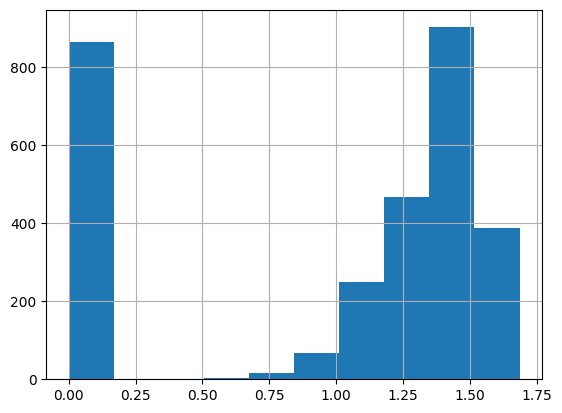

In [8]:
# Transformasi Discount
data_df['Discount'] = data_df['Discount'].apply(np.log1p)

# Histogram
data_df['Discount'].hist()
plt.show()

Memisahkan Variabel X dan Y + Train Test Split

In [11]:
# Pisahkan variabel independen
X = pd.concat([X_labels, X_dummies, data_df['Discount']], axis=1)

# Ambil target dari dataset asli
original_data = pd.read_csv(dataset)

y = original_data['Label'].map({
    'Profit': 1,
    'Loss': 0
})

# Cek missing values
print("Missing values X:", X.isna().sum().sum())
print("Missing values y:", y.isna().sum())

print("Shape X:", X.shape)
print("Shape y:", y.shape)

# Train Test Split dengan rasio 75:25
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=0
)

print('Data Training: X', X_train.shape, 'Y', y_train.shape)
print('Data Test: X', X_test.shape, 'Y', y_test.shape)

Missing values X: 0
Missing values y: 0
Shape X: (2955, 19)
Shape y: (2955,)
Data Training: X (2216, 19) Y (2216,)
Data Test: X (739, 19) Y (739,)


Decision Tree

In [13]:
# Bangun model Decision Tree
dt_mod = DecisionTreeClassifier(random_state=0)

# Training model
dt_mod.fit(X_train, y_train)

# Prediksi data training dan testing
y_pred_train = dt_mod.predict(X_train)
y_pred_test = dt_mod.predict(X_test)

Evaluasi Model Decision Tree

In [14]:
# Akurasi Training
acc_train = accuracy_score(y_train, y_pred_train)

# Akurasi Testing
acc_test = accuracy_score(y_test, y_pred_test)

print('Akurasi Training', acc_train)
print('Akurasi Testing', acc_test)

# Classification Report
print(classification_report(y_test, y_pred_test))

Akurasi Training 1.0
Akurasi Testing 0.8376184032476319
              precision    recall  f1-score   support

           0       0.61      0.60      0.61       154
           1       0.90      0.90      0.90       585

    accuracy                           0.84       739
   macro avg       0.75      0.75      0.75       739
weighted avg       0.84      0.84      0.84       739



Gradient Boosting

In [15]:
# Bangun model Gradient Boosting
gb_mod = GradientBoostingClassifier(random_state=0)

# Training model
gb_mod.fit(X_train, y_train)

# Prediksi data training dan testing
y_pred_train = gb_mod.predict(X_train)
y_pred_test = gb_mod.predict(X_test)

Evaluasi Gradient Boosting

In [16]:
# Akurasi Training
acc_train = accuracy_score(y_train, y_pred_train)

# Akurasi Testing
acc_test = accuracy_score(y_test, y_pred_test)

print('Akurasi Training', acc_train)
print('Akurasi Testing', acc_test)

# Classification Report
print(classification_report(y_test, y_pred_test))

Akurasi Training 0.9169675090252708
Akurasi Testing 0.8849797023004059
              precision    recall  f1-score   support

           0       0.78      0.63      0.70       154
           1       0.91      0.95      0.93       585

    accuracy                           0.88       739
   macro avg       0.84      0.79      0.81       739
weighted avg       0.88      0.88      0.88       739



Confusion Matrix (Tambahan visualisasi)

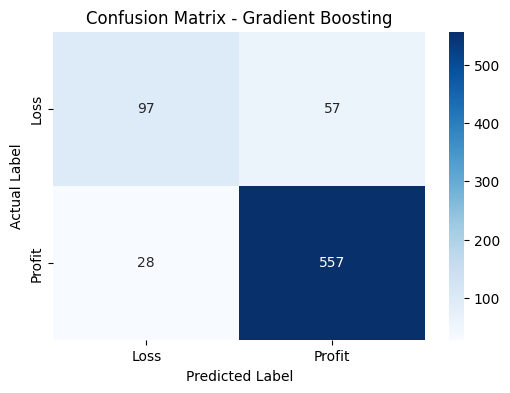

In [17]:
# Confusion Matrix Gradient Boosting
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Loss', 'Profit'],
    yticklabels=['Loss', 'Profit']
)

plt.title('Confusion Matrix - Gradient Boosting')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

## Kesimpulan

Berdasarkan hasil pengujian, model Gradient Boosting memiliki performa yang lebih baik dibandingkan Decision Tree dalam memprediksi kategori Profit dan Loss. Gradient Boosting memperoleh akurasi training sebesar 91,70% dan akurasi testing sebesar 88,50%. Sementara itu, Decision Tree memperoleh akurasi training sebesar 100% dan akurasi testing sebesar 83,76%.

Meskipun Decision Tree memiliki akurasi training yang lebih tinggi, terdapat penurunan performa yang cukup besar ketika diuji menggunakan data testing. Hal ini menunjukkan adanya indikasi overfitting. Sebaliknya, Gradient Boosting memiliki selisih akurasi training dan testing yang lebih kecil sehingga kemampuan generalisasinya lebih baik.

Dengan demikian, Gradient Boosting merupakan model yang lebih optimal berdasarkan hasil evaluasi karena memiliki akurasi testing lebih tinggi dan performa prediksi yang lebih seimbang dibandingkan Decision Tree.